# Stability and Accuracy of Schemes for Advection and Diffusion

In this notebook you will test several finite-difference schemes on the advection equation

$$\frac{\partial u}{\partial t}=-c\frac{\partial u}{\partial x},$$

and the diffusion equation, and see how the **Courant number** $\nu=c\,\Delta t/\Delta x$ controls stability and accuracy. The lesson notes ([stability](../notes/03-stability-cfl-and-von-neumann.md) and [schemes](../notes/04-upwind-lax-and-implicit-schemes.md)) give the theory.

Cells marked **TODO** in the student version are left for you to fill in.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (7, 3.5)

## Setup

A periodic domain $x\in[0,2)$ with a square wave, so we can run long enough for the wave to travel around the domain and compare with the exact solution $u(x,t)=f(x-ct)$ (wrapped periodically).

In [2]:
nx = 100
L = 2.0
dx = L / nx
x = np.arange(nx) * dx
c = 1.0

def initial_condition(x):
    u = np.ones_like(x)
    u[(x >= 0.5) & (x <= 1.0)] = 2.0
    return u

def exact(x, t):
    return initial_condition((x - c * t) % L)

u0 = initial_condition(x)

## The schemes

On a periodic grid, `np.roll(u, 1)[i]` is $u_{i-1}$ and `np.roll(u, -1)[i]` is $u_{i+1}$, so each scheme becomes one line. With $\nu=c\,\Delta t/\Delta x$:

| Scheme | Update |
|---|---|
| FTBS (upwind) | $u_i^{n+1}=u_i^n-\nu\,(u_i^n-u_{i-1}^n)$ |
| FTCS | $u_i^{n+1}=u_i^n-\tfrac{\nu}{2}\,(u_{i+1}^n-u_{i-1}^n)$ |
| Lax | $u_i^{n+1}=\tfrac12(u_{i+1}^n+u_{i-1}^n)-\tfrac{\nu}{2}\,(u_{i+1}^n-u_{i-1}^n)$ |
| Lax-Wendroff | $u_i^{n+1}=u_i^n-\tfrac{\nu}{2}(u_{i+1}^n-u_{i-1}^n)+\tfrac{\nu^2}{2}(u_{i+1}^n-2u_i^n+u_{i-1}^n)$ |

In [3]:
def step(u, nu, scheme):
    um = np.roll(u, 1)    # u_{i-1}
    up = np.roll(u, -1)   # u_{i+1}
    if scheme == 'FTBS':
        return u - nu * (u - um)
    if scheme == 'FTCS':
        return u - 0.5 * nu * (up - um)
    if scheme == 'Lax':
        return 0.5 * (up + um) - 0.5 * nu * (up - um)
    if scheme == 'Lax-Wendroff':
        return u - 0.5 * nu * (up - um) + 0.5 * nu**2 * (up - 2*u + um)
    raise ValueError(scheme)

In [4]:
def run(scheme, nu, t_end):
    dt = nu * dx / c
    nt = int(round(t_end / dt))
    u = u0.copy()
    for n in range(nt):
        u = step(u, nu, scheme)
    return u, nt * dt

## Experiment 1: Courant number and stability

Run each scheme to $t=0.5$ with $\nu=0.5$ and look at the solution against the exact one.

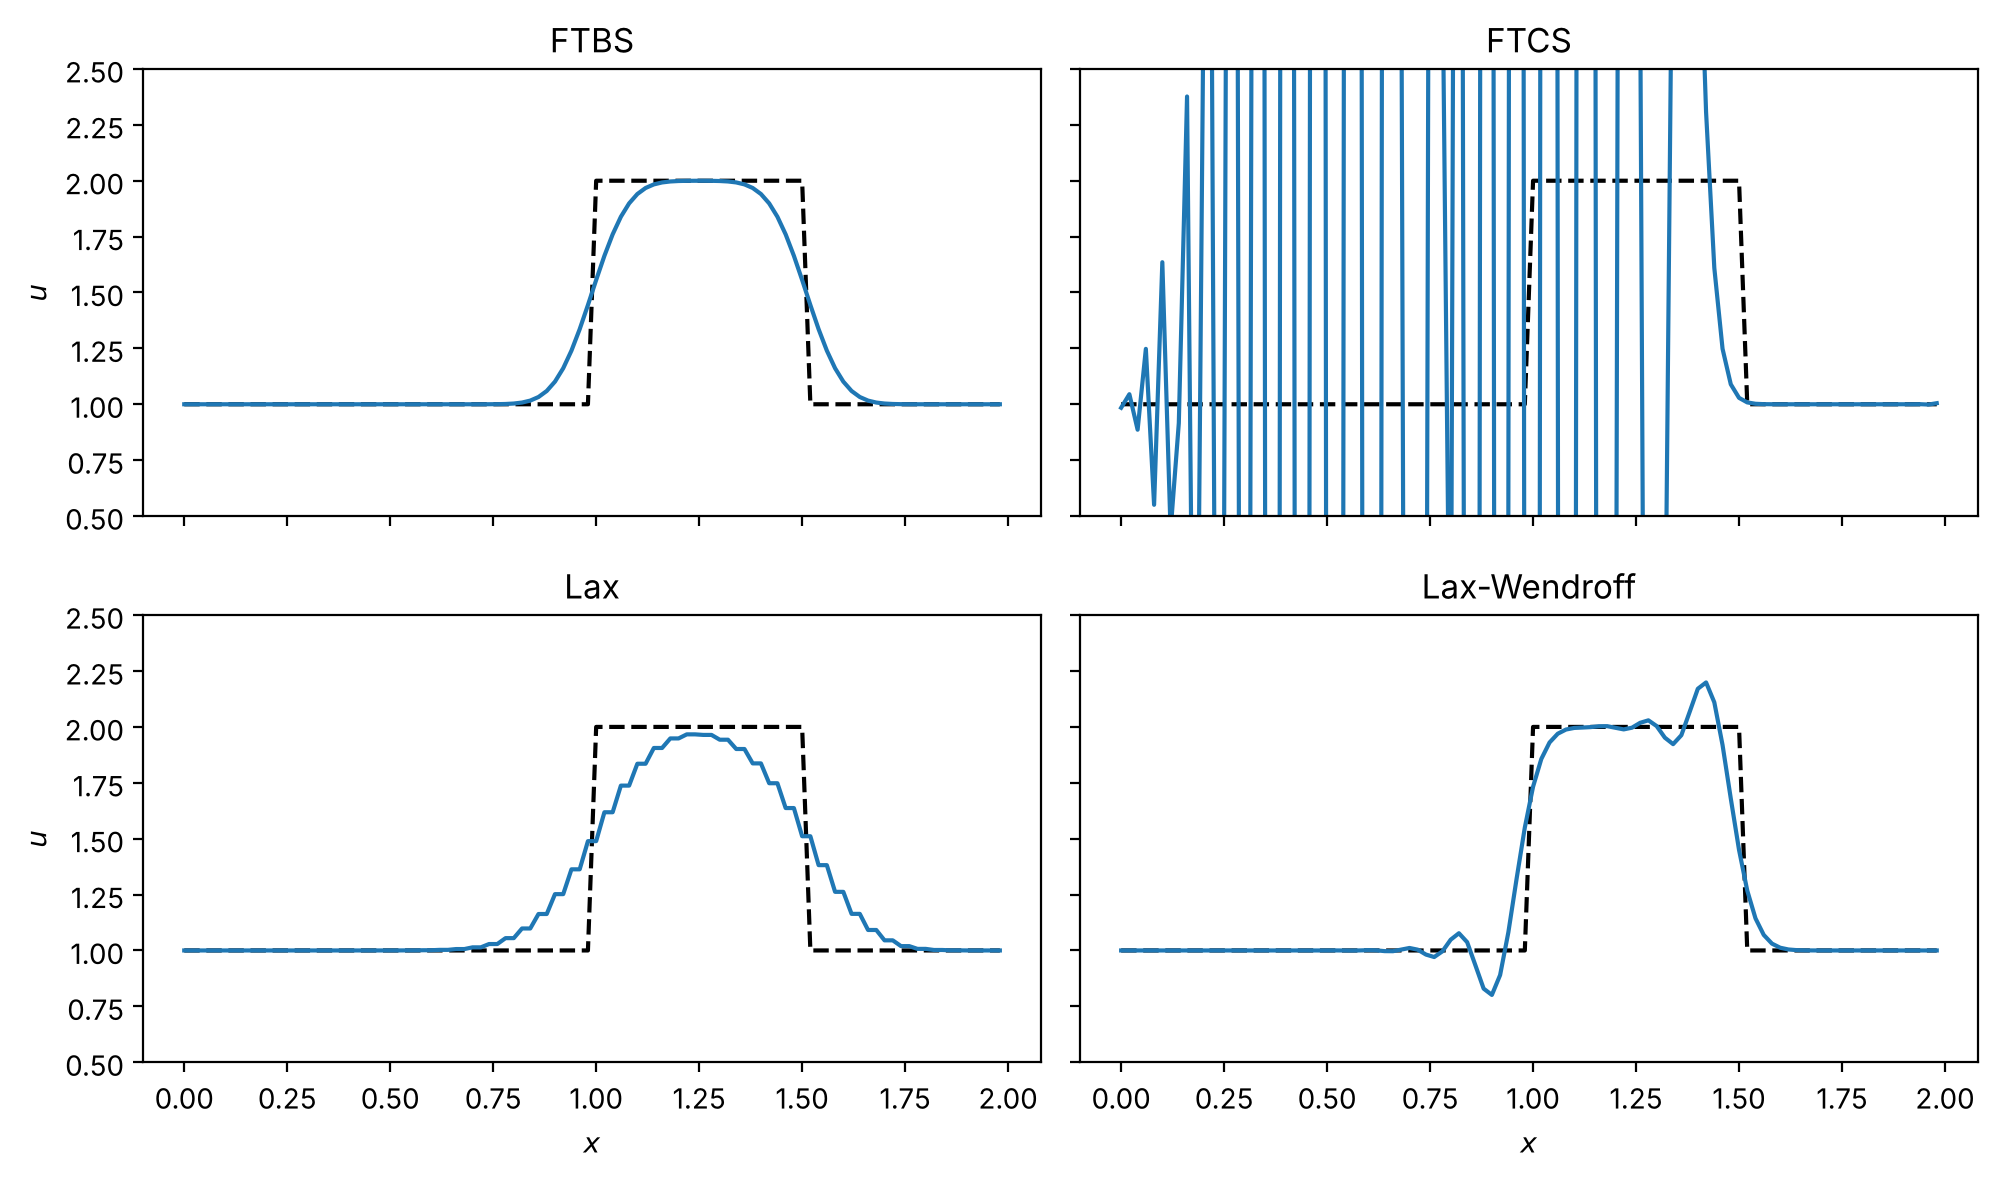

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, scheme in zip(axes.ravel(), ['FTBS', 'FTCS', 'Lax', 'Lax-Wendroff']):
    u, t = run(scheme, 0.5, 0.5)
    ax.plot(x, exact(x, t), 'k--', label='exact')
    ax.plot(x, u, label=scheme)
    ax.set_title(scheme); ax.set_ylim(0.5, 2.5)
for ax in axes[1]: ax.set_xlabel('$x$')
for ax in axes[:, 0]: ax.set_ylabel('$u$')
plt.tight_layout()

**Questions.** Which schemes smear the front? Which add wiggles? Which blows up? (FTCS is unstable here even though it is second-order accurate in space.)

Now vary $\nu$ for FTBS. Plot the maximum of $|u|$ after 200 steps against $\nu$ to find the stability limit.

Text(0, 0.5, '$\\max|u|$ after 200 steps')

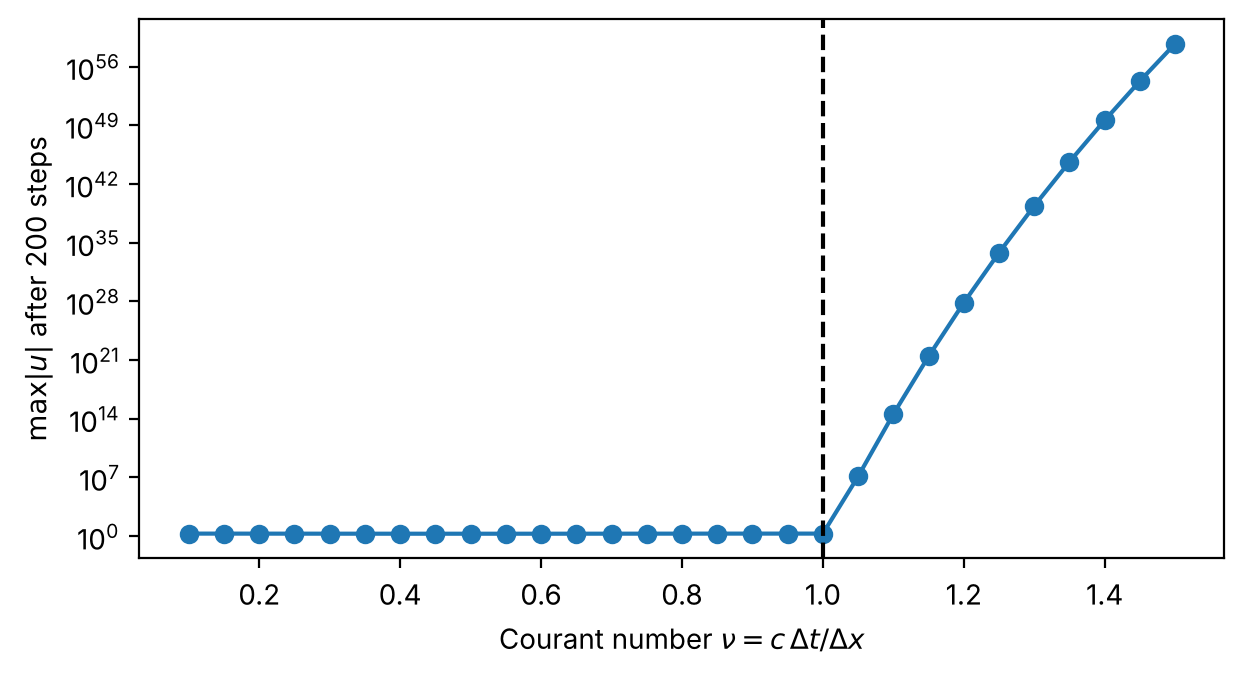

In [6]:
nus = np.linspace(0.1, 1.5, 29)
umax = []
for nu in nus:
    u = u0.copy()
    for n in range(200):
        u = step(u, nu, 'FTBS')
    umax.append(np.max(np.abs(u)))

fig, ax = plt.subplots()
ax.semilogy(nus, umax, 'o-')
ax.axvline(1.0, color='k', ls='--')
ax.set_xlabel(r'Courant number $\nu=c\,\Delta t/\Delta x$')
ax.set_ylabel(r'$\max|u|$ after 200 steps')

FTBS is stable for $0<\nu\le1$ (the CFL condition: the numerical domain of dependence must contain the physical one) and grows without bound for $\nu>1$.

## Experiment 2: numerical diffusion

At $\nu=1$ FTBS is exact for this problem. For smaller $\nu$ it smears the square wave. Compare $\nu=0.25,0.5,0.9,1.0$ at $t=1.0$.

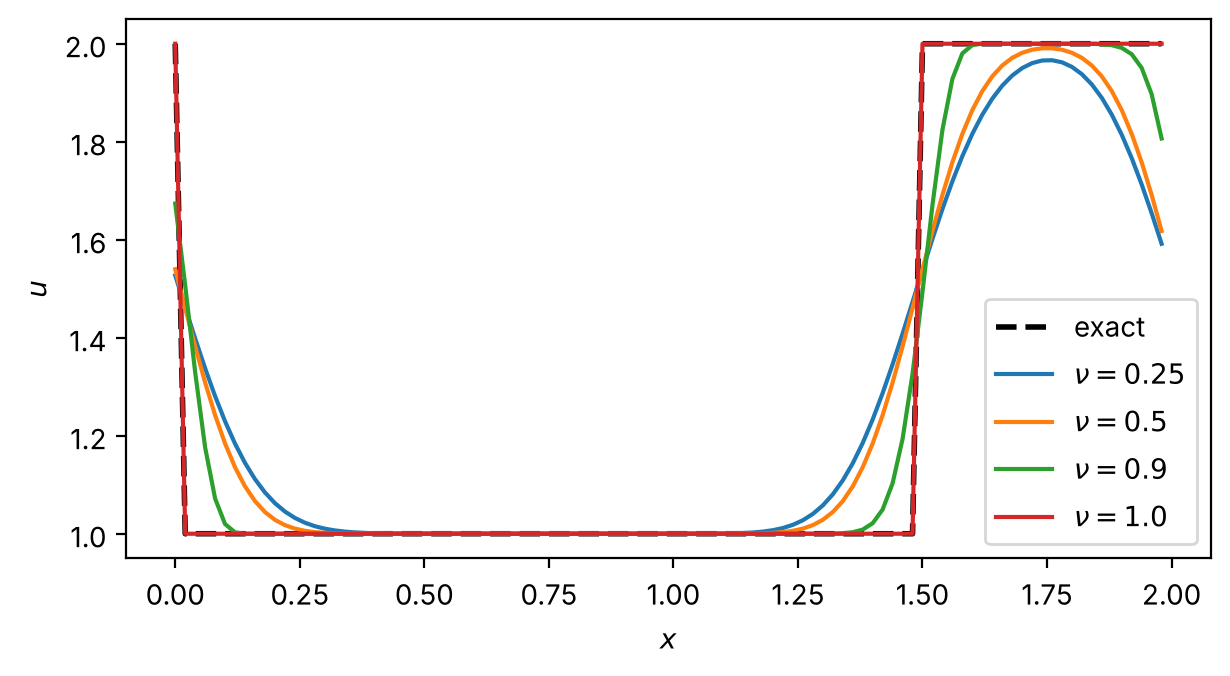

In [7]:
fig, ax = plt.subplots()
ax.plot(x, exact(x, 1.0), 'k--', lw=2, label='exact')
for nu in [0.25, 0.5, 0.9, 1.0]:
    u, t = run('FTBS', nu, 1.0)
    ax.plot(x, u, label=f'$\\nu={nu}$')
ax.set_xlabel('$x$'); ax.set_ylabel('$u$'); ax.legend()

The smearing is an artificial diffusion with coefficient $\nu_{num}=\tfrac{c\,\Delta x}{2}(1-\nu)$, which you can derive from the truncation error (see the lesson notes). It shrinks as $\nu\to1$ and as $\Delta x\to0$.

**Convergence.** Compute the RMS error at $t=1$ for $nx=50,100,200,400$ at fixed $\nu=0.5$ for FTBS and Lax-Wendroff, and plot against $\Delta x$ on log-log axes.

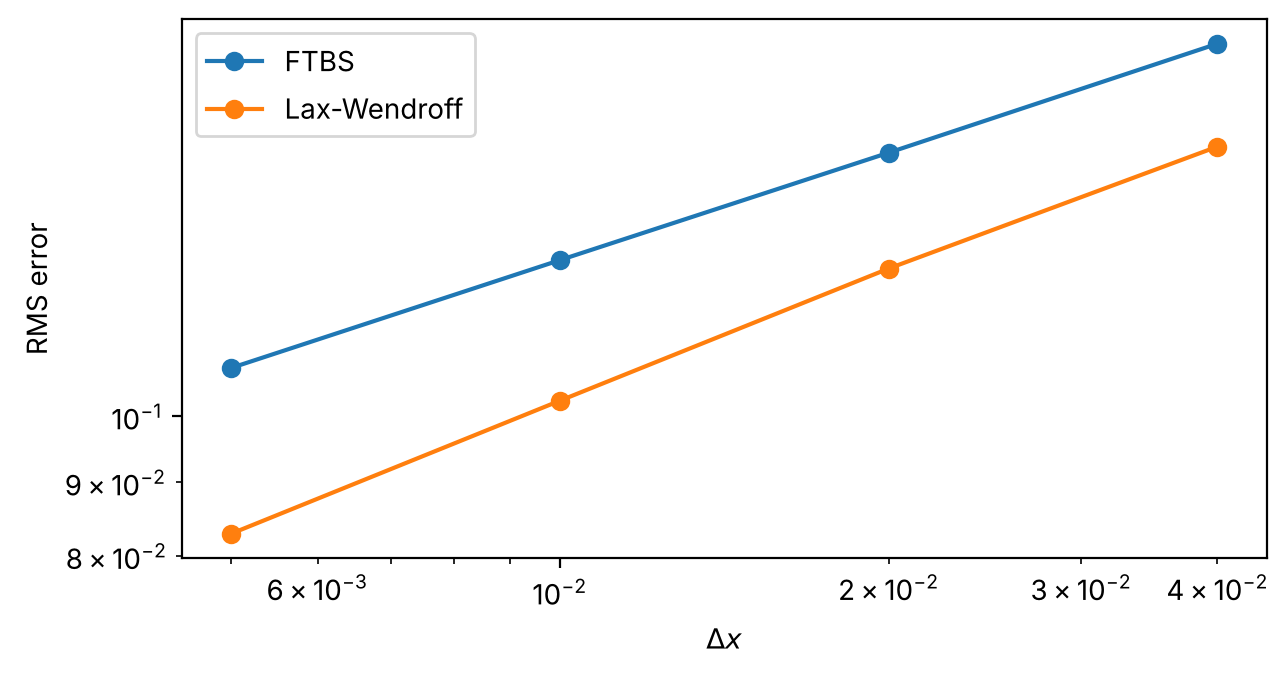

In [8]:
def rms_error(scheme, nx_, nu):
    global nx, dx, x, u0
    nx, dx = nx_, L / nx_
    x = np.arange(nx) * dx
    u0 = initial_condition(x)
    u, t = run(scheme, nu, 1.0)
    return dx, np.sqrt(np.mean((u - exact(x, t))**2))

fig, ax = plt.subplots()
for scheme in ['FTBS', 'Lax-Wendroff']:
    res = np.array([rms_error(scheme, n, 0.5) for n in [50, 100, 200, 400]])
    ax.loglog(res[:, 0], res[:, 1], 'o-', label=scheme)
ax.set_xlabel(r'$\Delta x$'); ax.set_ylabel('RMS error'); ax.legend()

# restore the original grid
nx = 100; dx = L / nx; x = np.arange(nx) * dx; u0 = initial_condition(x)

For a discontinuous profile the observed convergence rate in the RMS norm is far below the formal order of accuracy (about $1/4$ for FTBS and about $1/3$ for Lax-Wendroff here), because the error is concentrated at the jumps. Repeat with a smooth initial condition such as $1+\sin(\pi x)$ and compare with the formal orders (1 and 2).

## Experiment 3: von Neumann amplification factors

For a Fourier mode $u_i^n=G^n e^{ik x_i}$ and $\theta=k\,\Delta x$, each scheme gives an amplification factor $G(\theta)$. A scheme is stable if $|G|\le1$ for all $\theta$. For the schemes above:

- FTBS: $G=1-\nu(1-e^{-i\theta})$
- FTCS: $G=1-i\nu\sin\theta$
- Lax: $G=\cos\theta-i\nu\sin\theta$
- Lax-Wendroff: $G=1-i\nu\sin\theta-\nu^2(1-\cos\theta)$

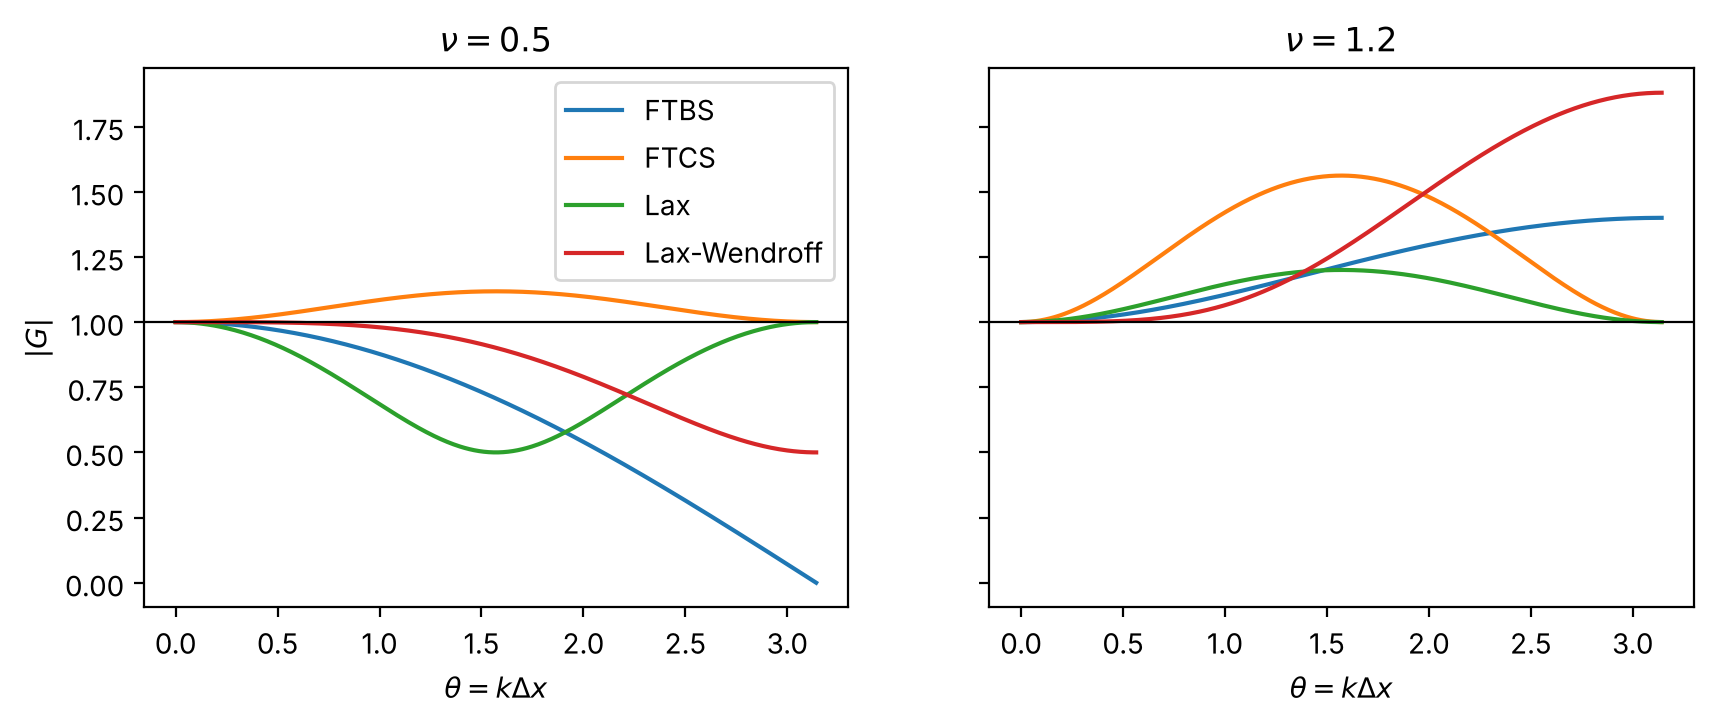

In [9]:
theta = np.linspace(0, np.pi, 400)
def G(scheme, nu, th):
    if scheme == 'FTBS':         return 1 - nu * (1 - np.exp(-1j * th))
    if scheme == 'FTCS':         return 1 - 1j * nu * np.sin(th)
    if scheme == 'Lax':          return np.cos(th) - 1j * nu * np.sin(th)
    if scheme == 'Lax-Wendroff': return 1 - 1j * nu * np.sin(th) - nu**2 * (1 - np.cos(th))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, nu in zip(axes, [0.5, 1.2]):
    for scheme in ['FTBS', 'FTCS', 'Lax', 'Lax-Wendroff']:
        ax.plot(theta, np.abs(G(scheme, nu, theta)), label=scheme)
    ax.axhline(1, color='k', lw=0.8)
    ax.set_title(rf'$\nu={nu}$'); ax.set_xlabel(r'$\theta=k\Delta x$')
axes[0].set_ylabel('$|G|$'); axes[0].legend()

Check that the plots agree with your runs: FTCS has $|G|>1$ for every $\theta>0$ (always unstable); the other three stay below 1 for $\nu=0.5$ and exceed 1 for $\nu=1.2$. Where is $|G|$ smallest? Those are the wavelengths each scheme damps most (the sharp edges of the square wave), which is why the fronts smear.

## Experiment 4: the diffusion equation

For $\partial u/\partial t=\nu_d\,\partial^2u/\partial x^2$ the FTCS scheme is

$$u_i^{n+1}=u_i^n+r\,(u_{i+1}^n-2u_i^n+u_{i-1}^n),\qquad r=\frac{\nu_d\,\Delta t}{\Delta x^2}.$$

Its stability limit is $r\le1/2$. Test it with a spike initial condition.

Text(0, 0.5, '$u$')

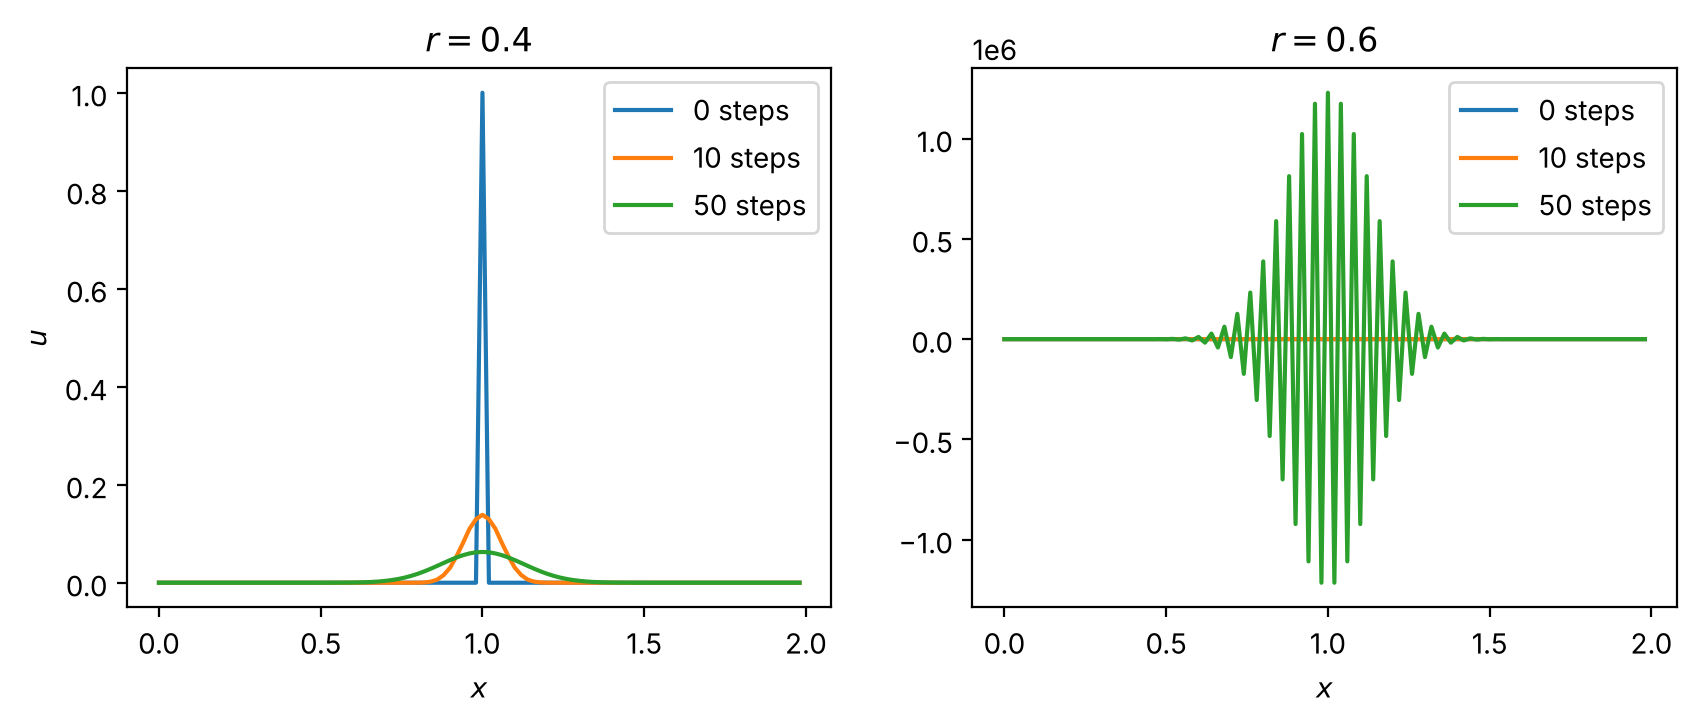

In [10]:
def diffuse(r, nsteps):
    u = np.zeros(nx); u[nx // 2] = 1.0
    for n in range(nsteps):
        u = u + r * (np.roll(u, -1) - 2 * u + np.roll(u, 1))
    return u

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, r in zip(axes, [0.4, 0.6]):
    for ns in [0, 10, 50]:
        ax.plot(x, diffuse(r, ns), label=f'{ns} steps')
    ax.set_title(f'$r={r}$'); ax.set_xlabel('$x$'); ax.legend()
axes[0].set_ylabel('$u$')

## Exercises

1. For FTBS, show from the amplification factor that $|G|^2=1-2\nu(1-\nu)(1-\cos\theta)$, and hence that $|G|\le1$ for all $\theta$ if and only if $0\le\nu\le1$.
2. Combine the two processes: add the diffusion term to FTBS to solve $u_t+c\,u_x=\nu_d\,u_{xx}$. Derive the amplification factor, find the stability limit on $\Delta t$ in terms of $\nu$ and $r$, and confirm it numerically.
3. Use your solver to explore the kerosene-spill exercise in this module's [exercise](../exercises/advection-diffusion-spill/index.md).